---
_Poner un ejemplo de cómo se puede quitar y cómo se puede generar en OpenCV/NumPy_

Fecha: martes 20 de octubre

Temas para exponer:

* ¿Qué es el ruido en imágenes? (SNR/PSNR)  Pablo Mariño ✅
* Ruido Gaussiano  Sebas ✅
* Ruido Sal y Pimienta (Impulsivo) Sofía ✅
* Ruido Speckle Javier ✅
* Ruido de Poisson Carlos ✅
* Ruido de Cuantización Max et. al. ✅

# Histogramas

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

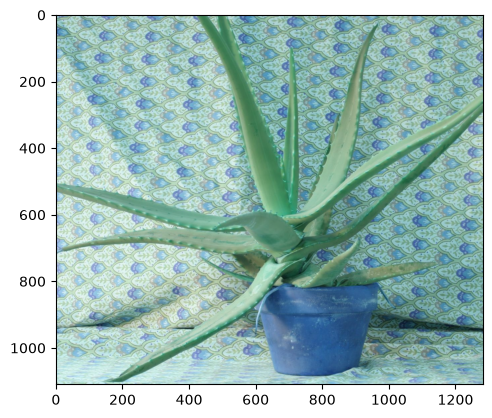

In [2]:
img = cv.imread("/Users/miguelcamargorojas/iCloud Drive (Archive)/Documents/UP/PDI-Ago-dic26/PDI-Ago-dic26-Gpo1/images/aloeR.jpg")
plt.imshow(img)
plt.show()

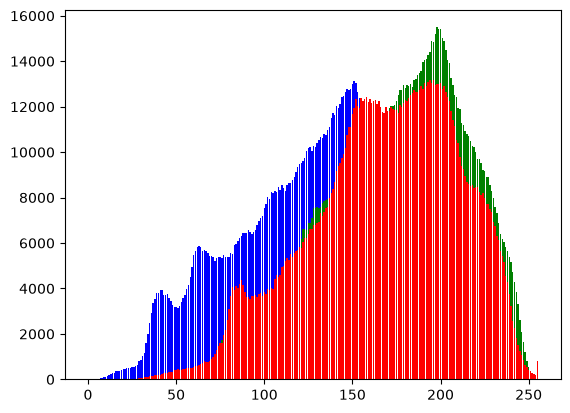

In [13]:
colores = ['b', 'g', 'r']

for n, i in enumerate(colores):
    tmp = cv.calcHist([img], [n], None, [256], [0, 256])
    plt.bar(range(256), tmp, color=i)
plt.show()

## Ecualización del histograma

In [ ]:
# cv.equalizeHist(img) # No se puede ecualizar una imagen a color (al menos no directamente)

error: OpenCV(5.0.0) /Users/xperience/GHA-OpenCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/histogram.cpp:2530: error: (-215:Assertion failed) _src.type() == CV_8UC1 in function 'equalizeHist'


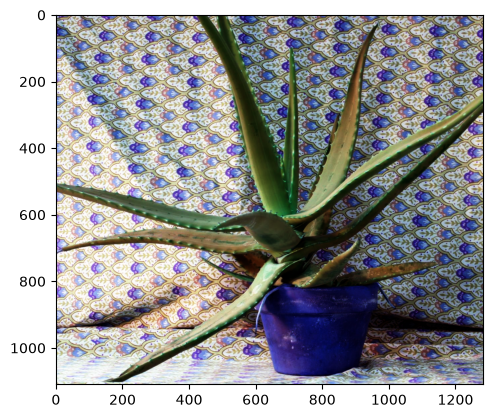

In [16]:
# ESTO NO SE HACE

# Ecualizar los 3 canales

for i in range(3):
    img[:, :, i] = cv.equalizeHist(img[:, :, i])

plt.imshow(img)
plt.show()

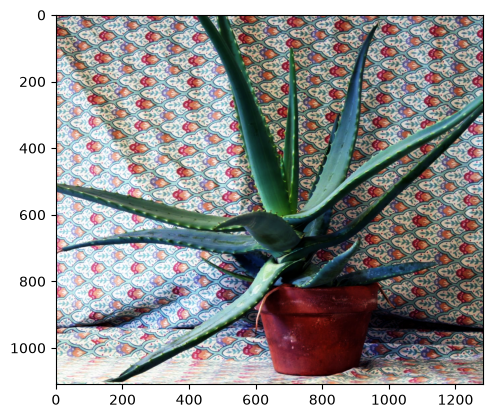

In [18]:
plt.imshow(img[:, :, ::-1])
plt.show()

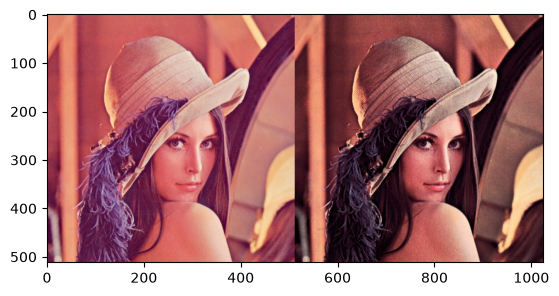

In [21]:
"""
Ecualizar canales en RGB/BGR solo introduce nuevos colores
porque cada canal es un color.

Entonces, usemos un espacio de color, que dedique uno de sus canales a la info
del brillo.

HSV: Hue/Saturation/Value(Brightness)
Conviene ecualizar V

1) Convertir espacio de color BGR -> HSV
2) Separar canales (H, S, V)
3) Ecualizar el canal de interés (V)
4) Unir los canales en una sola variable (con el canal ecualizado)
5) Volver al espacio original
6) Mostrar el resultado (opcional)
"""

lena_bgr = cv.imread('/Users/miguelcamargorojas/iCloud Drive (Archive)/Documents/UP/PDI-Ago-dic26/PDI-Ago-dic26-Gpo1/images/lena.jpg')
lena_hsv = cv.cvtColor(lena_bgr, cv.COLOR_BGR2HSV) # 1
h, s, v = cv.split(lena_hsv) # 2
v_eq = cv.equalizeHist(v) # 3
lena_hsv_veq = cv.merge((h, s, v_eq)) # 4
lena_rgb_eq = cv.cvtColor(lena_hsv_veq, cv.COLOR_HSV2RGB) # 5: está ya en RGB
plt.imshow(np.hstack((lena_bgr[:, :, ::-1], lena_rgb_eq))) # 6
plt.show()

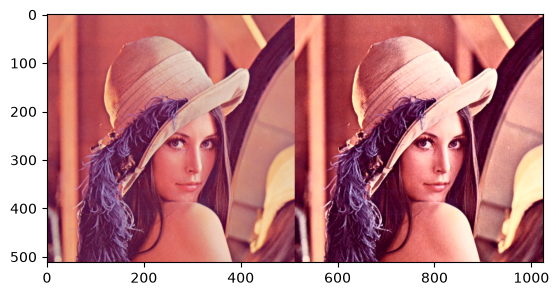

In [ ]:
"""
Ecualizar canales en RGB/BGR solo introduce nuevos colores
porque cada canal es un color.

Entonces, usemos un espacio de color, que dedique uno de sus canales a la info
del brillo.

YCbCr: Y (luminancia) Cromas rojo y azul
Conviene ecualizar Y

1) Convertir espacio de color BGR -> YCbCr
2) Separar canales (Y, Cb, Cr)
3) Ecualizar el canal de interés (Y)
4) Unir los canales en una sola variable (con el canal ecualizado)
5) Volver al espacio original cv.COLOR_BGR2YCrCb cv.COLOR_YCrCb2RGB
6) Mostrar el resultado (opcional)
"""

lena_ycrcb = cv.cvtColor(lena_bgr, cv.COLOR_BGR2YCrCb) # 1
y, cr, cb = cv.split(lena_ycrcb) # 2
y_eq = cv.equalizeHist(y) # 3
lena_ycrcb_yeq = cv.merge((y_eq, cr, cb)) # 4
lena_rgb_eq2 = cv.cvtColor(lena_ycrcb_yeq, cv.COLOR_YCrCb2RGB) # 5: está ya en RGB
plt.imshow(np.hstack((lena_bgr[:, :, ::-1], lena_rgb_eq2))) # 6
plt.show()
